<a href="https://colab.research.google.com/github/192412588simats-svg/CSA0208-C-Programming/blob/main/exp_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET
 Outlook Temperature Humidity   Wind Play
   Sunny         Hot     High   Weak   No
   Sunny         Hot     High Strong   No
Overcast         Hot     High   Weak  Yes
    Rain        Mild     High   Weak  Yes
    Rain        Cool   Normal   Weak  Yes
    Rain        Cool   Normal Strong   No
Overcast        Cool   Normal Strong  Yes
   Sunny        Mild     High   Weak   No
   Sunny        Cool   Normal   Weak  Yes
    Rain        Mild   Normal   Weak  Yes
   Sunny        Mild   Normal Strong  Yes
Overcast        Mild     High Strong  Yes
Overcast         Hot   Normal   Weak  Yes
    Rain        Mild     High Strong   No

INITIAL ENTROPY
Yes = 9
No  = 5
Entropy(S) = 0.9403

INFORMATION GAIN
Outlook: 0.2467
Temperature: 0.0292
Humidity: 0.1518
Wind: 0.0481

ROOT NODE = Outlook


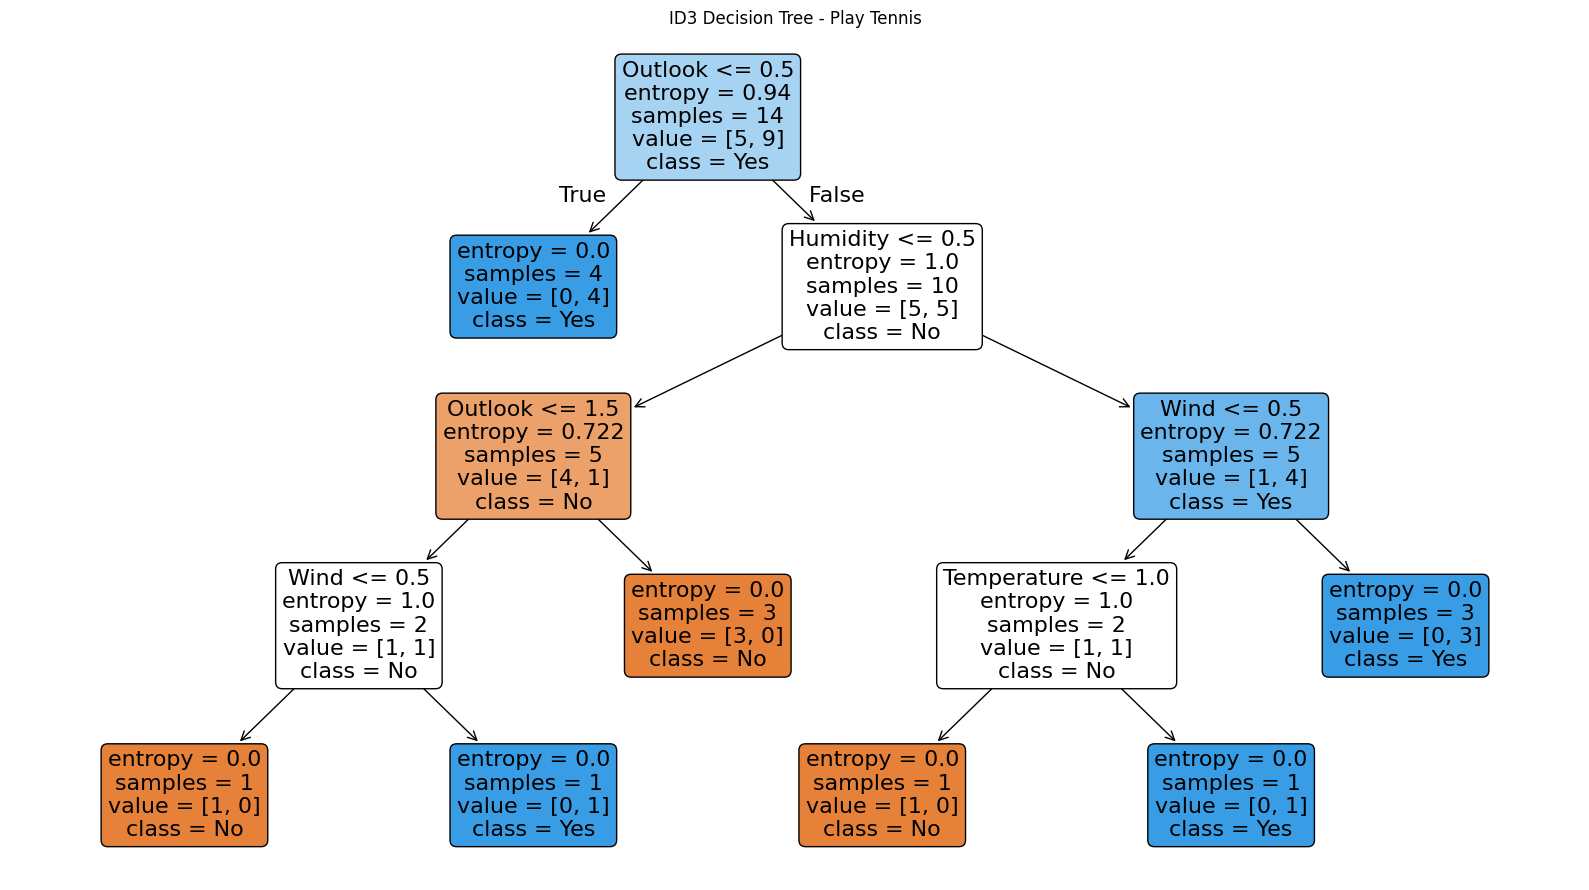


NEW SAMPLE
{'Outlook': 'Sunny', 'Temperature': 'Cool', 'Humidity': 'High', 'Wind': 'Strong'}
Predicted Play = No


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from math import log2

# 1. Dataset
data = {
    'Outlook': ['Sunny','Sunny','Overcast','Rain','Rain','Rain',
                'Overcast','Sunny','Sunny','Rain','Sunny','Overcast',
                'Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool',
                    'Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity': ['High','High','High','High','Normal','Normal','Normal',
                 'High','Normal','Normal','Normal','High','Normal','High'],
    'Wind': ['Weak','Strong','Weak','Weak','Weak','Strong','Strong',
             'Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play': ['No','No','Yes','Yes','Yes','No','Yes',
             'No','Yes','Yes','Yes','Yes','Yes','No']
}

df = pd.DataFrame(data)
print("DATASET")
print(df.to_string(index=False))

# 2. Entropy calculation
def entropy(labels):
    counts = labels.value_counts()
    total = len(labels)
    return -sum((count/total) * log2(count/total)
                for count in counts if count > 0)

def information_gain(df, attribute, target='Play'):
    total_entropy = entropy(df[target])
    weighted_entropy = 0

    for value in df[attribute].unique():
        subset = df[df[attribute] == value]
        weighted_entropy += (len(subset)/len(df)) * entropy(subset[target])

    return total_entropy - weighted_entropy

# 3. Initial entropy
print("\nINITIAL ENTROPY")
print("Yes =", (df['Play'] == 'Yes').sum())
print("No  =", (df['Play'] == 'No').sum())
print(f"Entropy(S) = {entropy(df['Play']):.4f}")

# 4. Information Gain
features = ['Outlook', 'Temperature', 'Humidity', 'Wind']
print("\nINFORMATION GAIN")

gains = {}
for feature in features:
    gains[feature] = information_gain(df, feature)
    print(f"{feature}: {gains[feature]:.4f}")

root = max(gains, key=gains.get)
print("\nROOT NODE =", root)

# 5. Encode categorical values
X = df[features].copy()
encoders = {}

for column in features:
    encoders[column] = LabelEncoder()
    X[column] = encoders[column].fit_transform(X[column])

y_encoder = LabelEncoder()
y = y_encoder.fit_transform(df['Play'])

# 6. Train ID3-style decision tree
model = DecisionTreeClassifier(
    criterion='entropy',
    splitter='best',
    random_state=42
)
model.fit(X, y)

# 7. Display graphical decision tree
plt.figure(figsize=(16, 9))
plot_tree(
    model,
    feature_names=features,
    class_names=list(y_encoder.classes_),
    filled=True,
    rounded=True,
    impurity=True
)
plt.title("ID3 Decision Tree - Play Tennis")
plt.tight_layout()
plt.show()

# 8. Classify a new sample
new_sample = {
    'Outlook': 'Sunny',
    'Temperature': 'Cool',
    'Humidity': 'High',
    'Wind': 'Strong'
}

new_df = pd.DataFrame([new_sample])

for column in features:
    new_df[column] = encoders[column].transform(new_df[column])

prediction = model.predict(new_df)[0]
predicted_class = y_encoder.inverse_transform([prediction])[0]

print("\nNEW SAMPLE")
print(new_sample)
print("Predicted Play =", predicted_class)
